# SkillPulse: Mapping Data & AI Skills in the Job Market

## 1. Project Overview

In [1]:
import requests                   # Get data from the web/API
import pandas as pd               # Store and analyze job data
import numpy as np                # Numerical calculations
import re                         # Find skills such as Python, SQL, Power BI inside text
import matplotlib.pyplot as plt   # Create charts
import seaborn as sns             # Create attractive statistical charts

## 2. Data Collection from Himalayas API

### 2.1 Test the Himalayas API

Send a request to the Himalayas public jobs API and inspect the response before collecting multiple batches.

In [3]:
url = "https://himalayas.app/jobs/api"

params = {
    "limit": 20
}

response = requests.get(url, params=params)

print("Status code:", response.status_code)

himalayas_data = response.json()

print("Total jobs available:", himalayas_data["totalCount"])
print("Jobs received:", len(himalayas_data["jobs"]))

Status code: 200
Total jobs available: 128940
Jobs received: 20


In [4]:
first_job = himalayas_data["jobs"][0]

print(first_job.keys())

dict_keys(['title', 'excerpt', 'companyName', 'companySlug', 'companyLogo', 'employmentType', 'minSalary', 'maxSalary', 'salaryPeriod', 'seniority', 'currency', 'locationRestrictions', 'timezoneRestrictions', 'categories', 'parentCategories', 'description', 'pubDate', 'expiryDate', 'applicationLink', 'guid'])


In [5]:
print(himalayas_data.keys())

dict_keys(['comments', 'updatedAt', 'offset', 'limit', 'totalCount', 'nextCursor', 'jobs'])


In [6]:
print(himalayas_data.get("nextCursor"))

MjAyNi0xMC0xOVQwMzozMjo0Ny4xNzExMjlafDI0Mjc2NDE


In [7]:
next_cursor = himalayas_data["nextCursor"]

params = {
    "limit": 20,
    "cursor": next_cursor
}

response = requests.get(
    "https://himalayas.app/jobs/api",
    params=params
)

print("Status code:", response.status_code)

next_data = response.json()

print("Jobs received:", len(next_data["jobs"]))
print("Next cursor:", next_data["nextCursor"])

Status code: 200
Jobs received: 20
Next cursor: MjAyNi0xMC0xOVQwMzoyNTo0OC41NDE5ODlafDI0MjUwNTE


In [8]:
print("First batch:")
print(himalayas_data["jobs"][0]["title"])

print("\nSecond batch:")
print(next_data["jobs"][0]["title"])

First batch:
Salesforce Order Management System Developer

Second batch:
Customer Service Agent II, Work from Home


### 2.2 Collect Multiple Batches of Jobs

Use cursor-based pagination to collect multiple batches. This notebook collects up to 200 postings in this run.

In [9]:
all_himalayas_jobs = []

next_cursor = None

for i in range(10):

    params = {
        "limit": 20
    }

    if next_cursor:
        params["cursor"] = next_cursor

    response = requests.get(
        "https://himalayas.app/jobs/api",
        params=params
    )

    result = response.json()

    jobs_batch = result["jobs"]

    all_himalayas_jobs.extend(jobs_batch)

    print(
        f"Request {i+1}: "
        f"{len(jobs_batch)} jobs collected"
    )

    next_cursor = result.get("nextCursor")

    if not next_cursor:
        print("No more jobs available.")
        break

print("\nTotal jobs collected:", len(all_himalayas_jobs))

Request 1: 20 jobs collected
Request 2: 20 jobs collected
Request 3: 20 jobs collected
Request 4: 20 jobs collected
Request 5: 20 jobs collected
Request 6: 20 jobs collected
Request 7: 20 jobs collected
Request 8: 20 jobs collected
Request 9: 20 jobs collected
Request 10: 20 jobs collected

Total jobs collected: 200


## 3. Explore the Raw Dataset

Convert the collected job records into a DataFrame and inspect its structure.

In [10]:
df_himalayas_raw = pd.DataFrame(all_himalayas_jobs)

print("Rows:", len(df_himalayas_raw))
print("Columns:", len(df_himalayas_raw.columns))

df_himalayas_raw.head()

Rows: 200
Columns: 20


,title,excerpt,companyName,companySlug,companyLogo,employmentType,minSalary,maxSalary,salaryPeriod,seniority,currency,locationRestrictions,timezoneRestrictions,categories,parentCategories,description,pubDate,expiryDate,applicationLink,guid
0,Salesforce Order Management System Developer,"We are Solu, the leading Ecommerce Accelerator...",Solu,solu,https://cdn-images.himalayas.app/b1c58etgicf06...,Full Time,NaN,NaN,annual,[Mid-level],None,[United States],"[-10, -9, -8, -7, -6, -5, 14]","[Salesforce-Developer, Salesforce-OMS, Order-M...",[Developer],"<p><strong>We are <a href=""https://himalayas.a...",1792381444,1797565443,https://himalayas.app/companies/solu/jobs/sale...,https://himalayas.app/companies/solu/jobs/sale...
1,Learning & Development Senior Program Manager,Company DescriptionGuardant Health is a leadin...,Guardant Health,guardant-health,https://cdn-images.himalayas.app/xwvtu79cbxqgk...,Full Time,145350.0,199878.0,annual,"[Senior, Manager]",USD,[United States],"[-10, -9, -8, -7, -6, -5, 14]","[Learning-and-Development, L&D-Program-Managem...",[Product],"<h3>Company Description</h3><p><a href=""https:...",1792381424,1797565423,https://himalayas.app/companies/guardant-healt...,https://himalayas.app/companies/guardant-healt...
2,AWS Cloud Engineer,ResponsibilitiesPeraton is seeking a motivated...,Peraton,peraton,https://cdn-images.himalayas.app/59ck8e7cbc0qt...,Full Time,104000.0,166000.0,annual,[Senior],USD,[United States],"[-10, -9, -8, -7, -6, -5, 14]","[AWS-Cloud-Engineer, Cloud-Engineer, DevOps-En...",[Developer],"<h3>Responsibilities</h3><p><a href=""https://h...",1792381394,1797565394,https://himalayas.app/companies/peraton/jobs/a...,https://himalayas.app/companies/peraton/jobs/a...
3,Full Stack Developer (m/w/d),ihre aufgaben • Technische Gesamtverantwortung...,KOMBO medical solutions UG,kombo-medical-solutions-ug,https://cdn-images.himalayas.app/lwr5eh9m1ytsa...,Full Time,NaN,NaN,annual,[Senior],None,[],"[-11, -10, -9.5, -9, -8, -7, -6, -5, -4, -3.5,...","[Full-Stack-Developer, Backend-Engineer, Softw...",[Developer],<h3>ihre aufgaben</h3><p></p><ul>\n<li>Technis...,1792381382,1797565381,https://himalayas.app/companies/kombo-medical-...,https://himalayas.app/companies/kombo-medical-...
4,Presales Solution Architect,"Marlabs, a global AI and Digital Solutions Con...",Marlabs Inc.,marlabs-inc,https://cdn-images.himalayas.app/o5wqypq9751tb...,Full Time,NaN,NaN,annual,[Senior],None,[United States],"[-10, -9, -8, -7, -6, -5, 14]","[Presales-Solution-Architect, Solutions-Archit...",[Developer],"<div class=""description"">\n<p>Marlabs, a globa...",1792381382,1797565381,https://himalayas.app/companies/marlabs-inc/jo...,https://himalayas.app/companies/marlabs-inc/jo...


In [11]:
print(df_himalayas_raw.columns)

Index(['title', 'excerpt', 'companyName', 'companySlug', 'companyLogo',
       'employmentType', 'minSalary', 'maxSalary', 'salaryPeriod', 'seniority',
       'currency', 'locationRestrictions', 'timezoneRestrictions',
       'categories', 'parentCategories', 'description', 'pubDate',
       'expiryDate', 'applicationLink', 'guid'],
      dtype='object')


### 3.1 Check for Duplicate Jobs

Check unique job identifiers and application links to understand whether duplicate postings were collected.

In [12]:
print("Total jobs:", len(df_himalayas_raw))

print(
    "Duplicate job IDs:",
    df_himalayas_raw["guid"].duplicated().sum()
)

print(
    "Duplicate application links:",
    df_himalayas_raw["applicationLink"].duplicated().sum()
)

Total jobs: 200
Duplicate job IDs: 0
Duplicate application links: 0


## 4. Check Data Quality

Review missing values before analyzing the dataset. Missing salary information should remain missing rather than being replaced with zero.

In [13]:
missing_values = df_himalayas_raw.isnull().sum()

print(missing_values)

title                    0
excerpt                  0
companyName              0
companySlug              0
companyLogo              0
employmentType           0
minSalary               97
maxSalary               97
salaryPeriod             0
seniority                0
currency                88
locationRestrictions     0
timezoneRestrictions     0
categories               0
parentCategories         0
description              0
pubDate                  0
expiryDate               0
applicationLink          0
guid                     0
dtype: int64


In [14]:
print(df_himalayas_raw["title"].head(20).to_string(index=False))

      Salesforce Order Management System Developer
     Learning & Development Senior Program Manager
                                AWS Cloud Engineer
                      Full Stack Developer (m/w/d)
                       Presales Solution Architect
                       Incident Commander (Tier 3)
                 Services Sales Manager & Complete
               Affiliate Manager, India & Pakistan
       Acquisition Manager - iGaming - Remote, SEA
                      Oracle Cloud Conversion Lead
                     Senior Benefit/Risk Associate
                         Channel Marketing Manager
                        Solution Engineer | Retail
                     Customer Education Specialist
            Senior Design Engineer Energy - Remote
Commercial Lead (Asia) Job - iGaming - Remote (...
  Stock Plan Administration Manager - Full Service
                          Customer Success Manager
            Senior Marketing Operations Specialist
Desenvolvimento Java Sênior Rem

In [15]:
print(df_himalayas_raw["seniority"].value_counts())

seniority
[Senior]                    64
[Mid-level]                 61
[Manager]                   23
[Entry-level]               19
[Director]                  11
[Executive]                  6
[Manager, Senior]            5
[Entry-level, Mid-level]     5
[Senior, Manager]            2
[Director, Executive]        2
[Senior, Director]           1
[Mid-level, Senior]          1
Name: count, dtype: int64


## 5. Filter Data & AI Job Postings

The API contains jobs from many fields. Build a focused dataset by searching job titles and category metadata for relevant Data & AI terms.

In [16]:
data_ai_keywords = [
    "data analyst",
    "data scientist",
    "data engineer",
    "machine learning",
    "ml engineer",
    "ai engineer",
    "artificial intelligence",
    "python developer"
]

print(data_ai_keywords)

['data analyst', 'data scientist', 'data engineer', 'machine learning', 'ml engineer', 'ai engineer', 'artificial intelligence', 'python developer']


### 5.1 Initial Title-Only Filter (Exploratory)

This first attempt searches job titles only. The broader filtering step below also includes categories, so it is the version used for the main analysis.

In [17]:
df_data_ai = df_himalayas_raw[
    df_himalayas_raw["title"].str.lower().apply(
        lambda title: any(keyword in title for keyword in data_ai_keywords)
    )
].copy()

print("Total Data & AI jobs:", len(df_data_ai))

Total Data & AI jobs: 3


In [18]:
print(df_data_ai["title"].to_string(index=False))


                       Manager - Data Engineering
                 Machine Learning Scientist (ASR)
Senior ML Engineer, AI Solutions (Greek-speaking)


In [19]:
print(df_data_ai["categories"].to_string(index=False))

[Data-Engineering, Engineering-Management, Data...
[Machine-Learning-Scientist, Applied-AI-Researc...
[Senior-ML-Engineer, Machine-Learning-Engineer,...


In [20]:
print(df_himalayas_raw["categories"].value_counts().head(30))

categories
[Salesforce-Developer, Salesforce-OMS, Order-Management-System-Developer, E-Commerce-Developer, CRM-Developer, Salesforce-CRM-Developer, Salesforce-Development, Salesforce-Solutions-Developer, Salesforce-Commerce-Developer, Salesforce-Application-Developer, Force.Com-Developer, Developer]                                                                                                                   1
[Ingénieur-En-Électricité, Ingénieur-Postes-Électriques-HTB, Electrical-Design-Engineer, Ingénieur-Infrastructure-Énergie, Chargé-D'études-BTP, Ingénieur-D'études-Postes-électriques-HTB]                                                                                                                                                                                                                          1
[Data-Analyst, Marketing-Analyst, Digital-Analyst, Business-Analyst, Analytics-Analyst, Senior-Analytics-Analyst, Senior-Analytics-Specialist, Senior-BI-And-Analytics-Analyst, S

In [21]:
print(df_data_ai[["title", "categories"]].to_string(index=False))

                                            title                                                                                                                                                                                                      categories
                       Manager - Data Engineering                                                                                          [Data-Engineering, Engineering-Management, Data-Pipeline-Engineering, Technology-Leadership, Data-Engineering-Manager]
                 Machine Learning Scientist (ASR)                             [Machine-Learning-Scientist, Applied-AI-Research, ASR-Research, Data-Science, Senior-Machine-Learning-Scientist, Staff-Machine-Learning-Scientist, Lead-Machine-Learning-Scientist]
Senior ML Engineer, AI Solutions (Greek-speaking) [Senior-ML-Engineer, Machine-Learning-Engineer, AI-Engineer, AI-Solutions-Engineer, Senior-AI-ML-Engineer, AI-ML-Solutions-Engineer, Senior-Applied-ML-Engineer, Senior-AI-ML-De

In [22]:
data_ai_keywords = [
    "data",
    "analytics",
    "business intelligence",
    "machine learning",
    "artificial intelligence",
    "ai",
    "python",
    "sql",
    "deep learning",
    "nlp",
    "data science",
    "data engineering",
    "data analyst",
    "data scientist",
    "data engineer",
    "ml engineer",
    "ai engineer"
]

### 5.2 Prepare Categories and Search Text

Categories are stored as lists, so combine their values into text that can be searched alongside job titles.

In [23]:
df_himalayas_raw["categories_text"] = df_himalayas_raw["categories"].apply(
    lambda x: " ".join(x) if isinstance(x, list) else str(x)
)

In [24]:
df_himalayas_raw["search_text"] = (
    df_himalayas_raw["title"].fillna("") + " " +
    df_himalayas_raw["categories_text"].fillna("")
).str.lower()

print(
    df_himalayas_raw[["title", "categories_text", "search_text"]]
    .head(5)
    .to_string(index=False)
)

                                        title                                                                                                                                                                                                                                                                                                                                                                                    categories_text                                                                                                                                                                                                                                                                                                                                                                                                                                      search_text
 Salesforce Order Management System Developer                                                                                         

In [25]:
role_keywords = [
    "data analyst",
    "data scientist",
    "data engineer",
    "data science",
    "data engineering",
    "machine learning",
    "ml engineer",
    "artificial intelligence",
    "ai engineer",
    "ai research",
    "business intelligence",
    "python developer",
    "python development",
    "analytics"
]

### 5.3 Create the Final Data & AI Dataset

Filter the collected postings using the selected role-related keywords and keep the matching rows in `df_data_ai`.

In [26]:
df_data_ai = df_himalayas_raw[
    df_himalayas_raw["search_text"].apply(
        lambda text: any(keyword in text for keyword in role_keywords)
    )
].copy()

print("Total Data & AI related jobs:", len(df_data_ai))

Total Data & AI related jobs: 13


In [27]:
print(
    df_data_ai[["title", "categories"]]
    .to_string(index=False)
)

                                                                           title                                                                                                                                                                                                                                       categories
                                          AI Research Scientist, Agentic Systems [AI-Research-Scientist, Research-Scientist, Data-Scientist, Machine-Learning-Scientist, AI-Scientist, Applied-AI-Research-Scientist, AI-ML-Research-Scientist, AI-Research-Scientist-Positions, Research-AI-Scientist, Agentic-Systems-Research]
                                                      Manager - Data Engineering                                                                                                                           [Data-Engineering, Engineering-Management, Data-Pipeline-Engineering, Technology-Leadership, Data-Engineering-Manager]
                                  

In [28]:
print(df_data_ai["title"].to_string(index=False))

            AI Research Scientist, Agentic Systems
                        Manager - Data Engineering
                      Manager - Advanced Analytics
                  Machine Learning Scientist (ASR)
Audit Technology and Data Analytics Expert, Dir...
Senior Analyst, Data & Analytics - No Surprises...
          Analytics Engineer, Finance and Modeling
                         Senior Analyst, Analytics
Data Vault Engineer - VaultSpeed / Snowflake / ...
Data Solutions - Manager Data Modeling and Data...
Chief Analytics Officer (CAO) — Insurance & Inv...
                          Visier Practice Director
 Senior ML Engineer, AI Solutions (Greek-speaking)


In [29]:
for keyword in role_keywords:
    count = df_data_ai["search_text"].str.contains(
        keyword,
        case=False,
        na=False
    ).sum()
    
    print(f"{keyword}: {count}")

data analyst: 0
data scientist: 0
data engineer: 1
data science: 1
data engineering: 1
machine learning: 1
ml engineer: 1
artificial intelligence: 0
ai engineer: 0
ai research: 1
business intelligence: 0
python developer: 0
python development: 0
analytics: 9


In [30]:
print("Total collected jobs:", len(df_himalayas_raw))
print("Data & AI related jobs:", len(df_data_ai))

Total collected jobs: 200
Data & AI related jobs: 13


## 6. Define Technical Skills to Search For

Create a keyword list of technical skills to identify in job descriptions. Keyword-based extraction is useful for a first version, but it may miss synonyms or context.

In [31]:
skill_keywords = [
    "python",
    "sql",
    "excel",
    "power bi",
    "tableau",
    "pandas",
    "numpy",
    "scikit-learn",
    "tensorflow",
    "pytorch",
    "machine learning",
    "deep learning",
    "natural language processing",
    "nlp",
    "artificial intelligence",
    "aws",
    "azure",
    "gcp",
    "spark",
    "hadoop",
    "snowflake",
    "databricks",
    "git",
    "github",
    "fastapi",
    "docker"
]

In [32]:
df_himalayas_raw["description"]

0      <p><strong>We are <a href="https://himalayas.a...
1      <h3>Company Description</h3><p><a href="https:...
2      <h3>Responsibilities</h3><p><a href="https://h...
3      <h3>ihre aufgaben</h3><p></p><ul>\n<li>Technis...
4      <div class="description">\n<p>Marlabs, a globa...
                             ...                        
195    <h3><b>Ready for a challenge?</b></h3><br><p>T...
196    <div class="description">\n<p>Reports to: CEO<...
197    <p><strong>Location:  </strong>This is a remot...
198    <h3>\n<b>Become a part of our caring community...
199    <p>At <b><a href="https://himalayas.app/compan...
Name: description, Length: 200, dtype: object

In [33]:
print(df_data_ai["description"].iloc[0])

<p>As a global leader in cybersecurity, CrowdStrike protects the people, processes and technologies that drive modern organizations. Since 2011, our mission hasn’t changed — we’re here to stop breaches, and we’ve redefined modern security with the world’s most advanced AI-native platform. We work on large scale distributed systems, processing almost 3 trillion events per day and this traffic is growing daily. Our customers span all industries, and they count on CrowdStrike to keep their businesses running, their communities safe and their lives moving forward. We're proud to work for a mission-driven company leveraging AI to transform the way we work. CrowdStrikers drive their careers through flexibility and autonomy while also being expected to contribute to a culture of responsible AI adoption, experimentation, and innovation. We use an AI-first mindset as a force multiplier to proactively and continuously accelerate execution, build expertise, uncover insights, and solve complex pro

## 7. Clean Job Description Text

Job descriptions may contain HTML tags. Convert them into readable text before searching for skill keywords.

In [34]:
from bs4 import BeautifulSoup

sample_description = df_data_ai["description"].iloc[0]

clean_description = BeautifulSoup(
    sample_description,
    "html.parser"
).get_text(" ", strip=True)

print(clean_description)

As a global leader in cybersecurity, CrowdStrike protects the people, processes and technologies that drive modern organizations. Since 2011, our mission hasn’t changed — we’re here to stop breaches, and we’ve redefined modern security with the world’s most advanced AI-native platform. We work on large scale distributed systems, processing almost 3 trillion events per day and this traffic is growing daily. Our customers span all industries, and they count on CrowdStrike to keep their businesses running, their communities safe and their lives moving forward. We're proud to work for a mission-driven company leveraging AI to transform the way we work. CrowdStrikers drive their careers through flexibility and autonomy while also being expected to contribute to a culture of responsible AI adoption, experimentation, and innovation. We use an AI-first mindset as a force multiplier to proactively and continuously accelerate execution, build expertise, uncover insights, and solve complex proble

In [35]:
df_data_ai["clean_description"] = df_data_ai["description"].apply(
    lambda x: BeautifulSoup(x, "html.parser").get_text(" ", strip=True)
)

In [36]:
print(df_data_ai["clean_description"].iloc[0])

As a global leader in cybersecurity, CrowdStrike protects the people, processes and technologies that drive modern organizations. Since 2011, our mission hasn’t changed — we’re here to stop breaches, and we’ve redefined modern security with the world’s most advanced AI-native platform. We work on large scale distributed systems, processing almost 3 trillion events per day and this traffic is growing daily. Our customers span all industries, and they count on CrowdStrike to keep their businesses running, their communities safe and their lives moving forward. We're proud to work for a mission-driven company leveraging AI to transform the way we work. CrowdStrikers drive their careers through flexibility and autonomy while also being expected to contribute to a culture of responsible AI adoption, experimentation, and innovation. We use an AI-first mindset as a force multiplier to proactively and continuously accelerate execution, build expertise, uncover insights, and solve complex proble

## 8. Extract Skills from Job Descriptions

Create a function that checks each cleaned description for the skill keywords and returns the skills found.

In [37]:
def extract_skills(text):
    text = text.lower()
    
    found_skills = []
    
    for skill in skill_keywords:
        if skill.lower() in text:
            found_skills.append(skill)
    
    return found_skills

In [38]:
df_data_ai["extracted_skills"] = df_data_ai["clean_description"].apply(
    extract_skills
)

In [39]:
print(
    df_data_ai[["title", "extracted_skills"]]
    .head(10)
    .to_string(index=False)
)

                                                                           title                                                                                  extracted_skills
                                          AI Research Scientist, Agentic Systems                               [python, excel, pytorch, machine learning, artificial intelligence]
                                                      Manager - Data Engineering                          [python, sql, excel, power bi, aws, azure, spark, snowflake, databricks]
                                                    Manager - Advanced Analytics                                                 [python, sql, excel, power bi, azure, databricks]
                                                Machine Learning Scientist (ASR)                                 [excel, machine learning, deep learning, artificial intelligence]
 Audit Technology and Data Analytics Expert, Director Analyst (REMOTE UK & EMEA)                         

## 9. Analyze Overall Skill Demand

Count how often each skill appears across the filtered job postings. Counts represent postings mentioning a skill, not necessarily unique people or hires.

In [40]:
from collections import Counter

skill_counts = Counter()

for skills in df_data_ai["extracted_skills"]:
    skill_counts.update(skills)

print(skill_counts)

Counter({'excel': 9, 'python': 8, 'sql': 8, 'power bi': 5, 'machine learning': 4, 'databricks': 4, 'tableau': 4, 'artificial intelligence': 3, 'aws': 3, 'azure': 3, 'snowflake': 3, 'spark': 2, 'git': 2, 'gcp': 2, 'pytorch': 1, 'deep learning': 1})


In [41]:
skill_counts.most_common()

[('excel', 9),
 ('python', 8),
 ('sql', 8),
 ('power bi', 5),
 ('machine learning', 4),
 ('databricks', 4),
 ('tableau', 4),
 ('artificial intelligence', 3),
 ('aws', 3),
 ('azure', 3),
 ('snowflake', 3),
 ('spark', 2),
 ('git', 2),
 ('gcp', 2),
 ('pytorch', 1),
 ('deep learning', 1)]

In [42]:
skill_df = pd.DataFrame(
    skill_counts.most_common(),
    columns=["Skill", "Job Count"]
)

print(skill_df)

                      Skill  Job Count
0                     excel          9
1                    python          8
2                       sql          8
3                  power bi          5
4          machine learning          4
5                databricks          4
6                   tableau          4
7   artificial intelligence          3
8                       aws          3
9                     azure          3
10                snowflake          3
11                    spark          2
12                      git          2
13                      gcp          2
14                  pytorch          1
15            deep learning          1


In [43]:
total_data_ai_jobs = len(df_data_ai)

skill_df["Demand %"] = (
    skill_df["Job Count"] / total_data_ai_jobs * 100
)

print(skill_df)

                      Skill  Job Count   Demand %
0                     excel          9  69.230769
1                    python          8  61.538462
2                       sql          8  61.538462
3                  power bi          5  38.461538
4          machine learning          4  30.769231
5                databricks          4  30.769231
6                   tableau          4  30.769231
7   artificial intelligence          3  23.076923
8                       aws          3  23.076923
9                     azure          3  23.076923
10                snowflake          3  23.076923
11                    spark          2  15.384615
12                      git          2  15.384615
13                      gcp          2  15.384615
14                  pytorch          1   7.692308
15            deep learning          1   7.692308


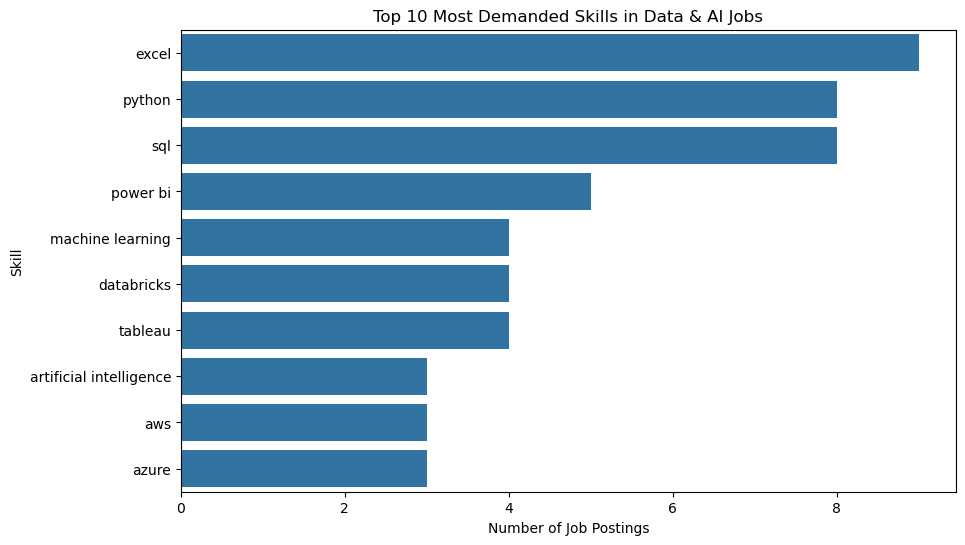

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

top_skills = skill_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_skills,
    x="Job Count",
    y="Skill"
)

plt.title("Top 10 Most Demanded Skills in Data & AI Jobs")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skill")

plt.show()

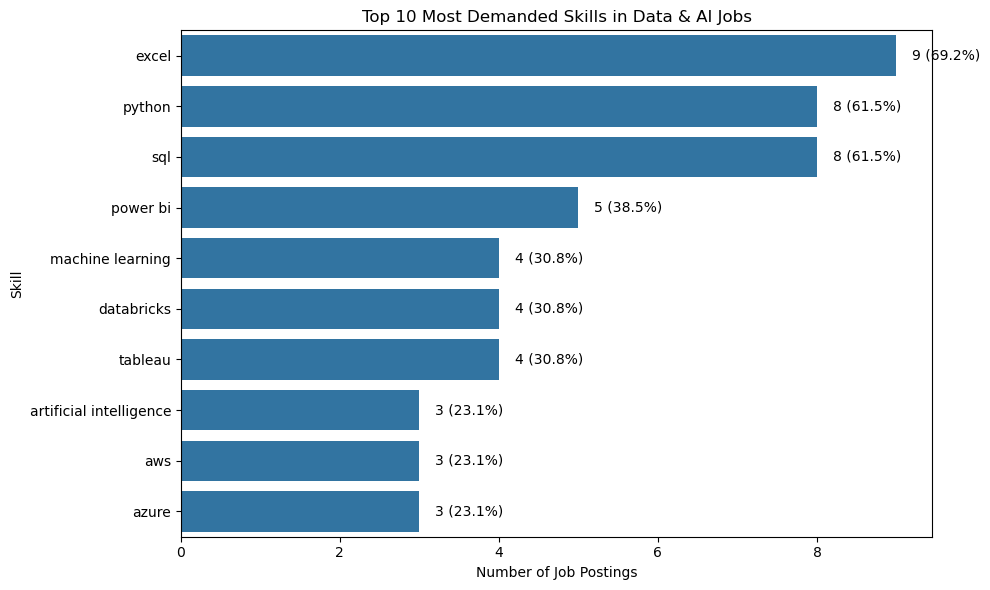

In [45]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=skill_df.head(10),
    x="Job Count",
    y="Skill"
)

plt.title("Top 10 Most Demanded Skills in Data & AI Jobs")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skill")

for i, row in skill_df.head(10).reset_index(drop=True).iterrows():
    ax.text(
        row["Job Count"] + 0.2,
        i,
        f'{row["Job Count"]} ({row["Demand %"]:.1f}%)',
        va="center"
    )

plt.tight_layout()
plt.show()

In [46]:
skill_df.to_csv(
    "../data/skill_demand.csv",
    index=False
)

## 10. Classify Job Roles

Assign a broad role label based on the job title. These labels depend on the keyword rules defined in the function.

In [47]:
def identify_role(title):
    title = title.lower()

    if "data analyst" in title:
        return "Data Analyst"
    elif "data scientist" in title:
        return "Data Scientist"
    elif "data engineer" in title:
        return "Data Engineer"
    elif "machine learning" in title or "ml engineer" in title:
        return "Machine Learning"
    elif "ai engineer" in title or "artificial intelligence" in title:
        return "AI Engineer"
    elif "python developer" in title:
        return "Python Developer"
    elif "business intelligence" in title:
        return "Business Intelligence"
    else:
        return "Other Data/AI"

In [48]:
df_data_ai["role"] = df_data_ai["title"].apply(identify_role)

In [49]:
print(
    df_data_ai[["title", "role"]]
    .to_string(index=False)
)

                                                                           title             role
                                          AI Research Scientist, Agentic Systems    Other Data/AI
                                                      Manager - Data Engineering    Data Engineer
                                                    Manager - Advanced Analytics    Other Data/AI
                                                Machine Learning Scientist (ASR) Machine Learning
 Audit Technology and Data Analytics Expert, Director Analyst (REMOTE UK & EMEA)    Other Data/AI
Senior Analyst, Data & Analytics - No Surprises Act/Provider Reimbursements/SQL     Other Data/AI
                                        Analytics Engineer, Finance and Modeling    Other Data/AI
                                                       Senior Analyst, Analytics    Other Data/AI
                       Data Vault Engineer - VaultSpeed / Snowflake / Databricks    Other Data/AI
                    

In [50]:
print(df_data_ai["role"].value_counts())

role
Other Data/AI       10
Machine Learning     2
Data Engineer        1
Name: count, dtype: int64


## 11. Compare Skills Across Job Roles

Count extracted skills separately for each role, then prepare the results for a heatmap.

In [51]:
role_skill_counts = {}

for role in df_data_ai["role"].unique():
    
    role_jobs = df_data_ai[
        df_data_ai["role"] == role
    ]
    
    counter = Counter()
    
    for skills in role_jobs["extracted_skills"]:
        counter.update(skills)
    
    role_skill_counts[role] = counter

In [52]:
print(role_skill_counts)

{'Other Data/AI': Counter({'excel': 7, 'python': 6, 'sql': 6, 'power bi': 4, 'tableau': 4, 'machine learning': 3, 'databricks': 3, 'artificial intelligence': 2, 'azure': 2, 'git': 2, 'snowflake': 2, 'pytorch': 1, 'aws': 1, 'gcp': 1, 'spark': 1}), 'Data Engineer': Counter({'python': 1, 'sql': 1, 'excel': 1, 'power bi': 1, 'aws': 1, 'azure': 1, 'spark': 1, 'snowflake': 1, 'databricks': 1}), 'Machine Learning': Counter({'excel': 1, 'machine learning': 1, 'deep learning': 1, 'artificial intelligence': 1, 'python': 1, 'sql': 1, 'aws': 1, 'gcp': 1})}


In [53]:
role_skill_df = pd.DataFrame(role_skill_counts).fillna(0)

print(role_skill_df)

                         Other Data/AI  Data Engineer  Machine Learning
python                             6.0            1.0               1.0
excel                              7.0            1.0               1.0
pytorch                            1.0            0.0               0.0
machine learning                   3.0            0.0               1.0
artificial intelligence            2.0            0.0               1.0
sql                                6.0            1.0               1.0
power bi                           4.0            1.0               0.0
azure                              2.0            1.0               0.0
databricks                         3.0            1.0               0.0
tableau                            4.0            0.0               0.0
git                                2.0            0.0               0.0
aws                                1.0            1.0               1.0
gcp                                1.0            0.0           

In [54]:
top_role_skills = role_skill_df.sum(axis=1).sort_values(
    ascending=False
).head(12).index

heatmap_data = role_skill_df.loc[top_role_skills]

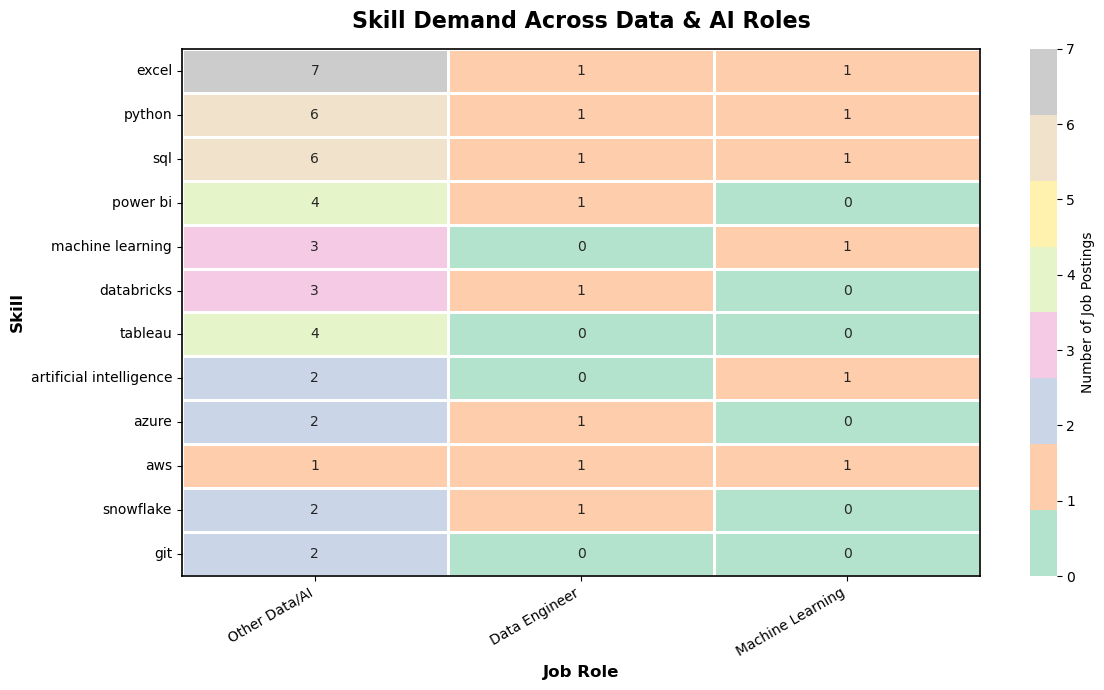

In [55]:
plt.figure(figsize=(12, 7))

ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="Pastel2",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Number of Job Postings"}
)

plt.title(
    "Skill Demand Across Data & AI Roles",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Job Role",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Skill",
    fontsize=12,
    fontweight="bold"
)

# Rotate labels for better readability
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

# Border around the complete chart
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 12. Analyze Skill Combinations

Count pairs of skills that appear together in the same posting to identify commonly co-mentioned technologies.

In [56]:
from itertools import combinations
from collections import Counter

skill_pairs = Counter()

for skills in df_data_ai["extracted_skills"]:
    
    # Remove duplicate skills within the same job
    skills = list(set(skills))
    
    # Create every possible pair
    pairs = combinations(sorted(skills), 2)
    
    skill_pairs.update(pairs)

In [57]:
top_skill_pairs = skill_pairs.most_common(15)

for pair, count in top_skill_pairs:
    print(f"{pair[0]} + {pair[1]} : {count}")

python + sql : 7
excel + python : 5
excel + sql : 5
power bi + sql : 5
databricks + python : 4
databricks + sql : 4
excel + power bi : 4
power bi + python : 4
sql + tableau : 4
artificial intelligence + excel : 3
excel + machine learning : 3
machine learning + python : 3
aws + python : 3
aws + sql : 3
azure + databricks : 3


In [58]:
pair_df = pd.DataFrame(
    top_skill_pairs,
    columns=["Skill Pair", "Job Count"]
)

pair_df["Skill Pair"] = pair_df["Skill Pair"].apply(
    lambda x: " + ".join(x)
)

print(pair_df)

                         Skill Pair  Job Count
0                      python + sql          7
1                    excel + python          5
2                       excel + sql          5
3                    power bi + sql          5
4               databricks + python          4
5                  databricks + sql          4
6                  excel + power bi          4
7                 power bi + python          4
8                     sql + tableau          4
9   artificial intelligence + excel          3
10         excel + machine learning          3
11        machine learning + python          3
12                     aws + python          3
13                        aws + sql          3
14               azure + databricks          3


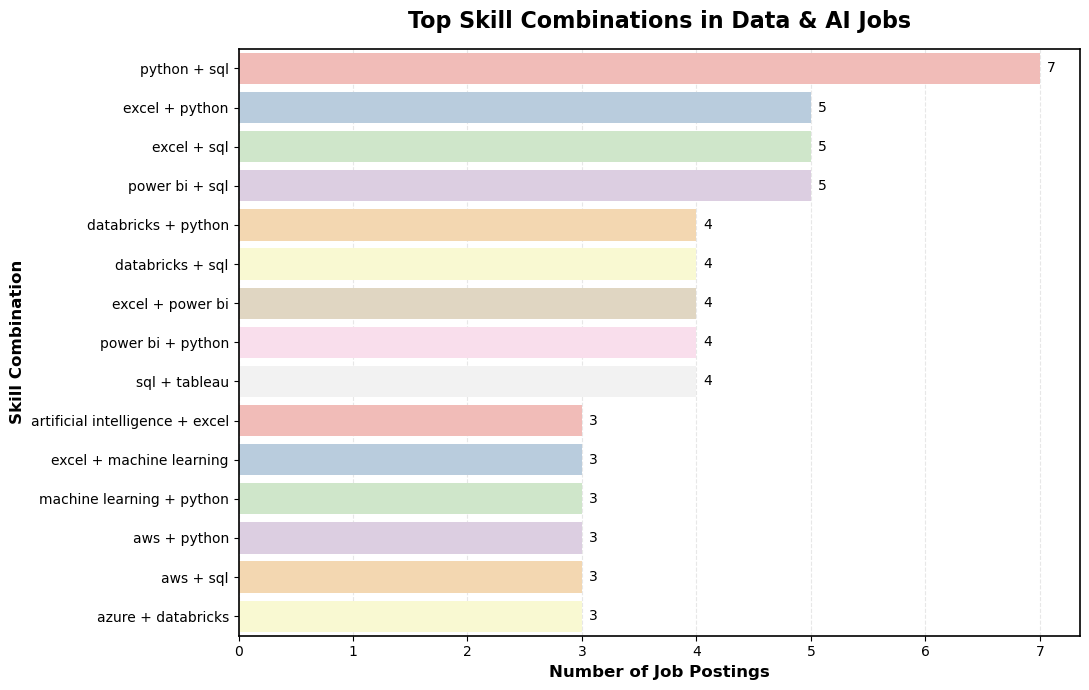

In [59]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=pair_df,
    x="Job Count",
    y="Skill Pair",
    palette="Pastel1",
    hue="Skill Pair",
    legend=False
)

plt.title(
    "Top Skill Combinations in Data & AI Jobs",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Skill Combination",
    fontsize=12,
    fontweight="bold"
)

# Add values at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=10
    )

# Light grid for readability
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# Keep grid behind bars
ax.set_axisbelow(True)

# Border around chart
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [60]:
print(
    df_data_ai["seniority"]
    .value_counts()
)

seniority
[Senior]       5
[Manager]      3
[Director]     2
[Mid-level]    2
[Executive]    1
Name: count, dtype: int64


## 13. Analyze Seniority Levels

Some postings contain more than one seniority label. Apply a consistent priority rule to assign one primary level for comparison.

In [61]:
def get_primary_seniority(levels):
    
    priority = [
        "Director",
        "Manager",
        "Senior",
        "Mid-level",
        "Entry-level"
    ]
    
    for level in priority:
        if level in levels:
            return level
    
    return "Unknown"

In [62]:
df_data_ai["primary_seniority"] = df_data_ai["seniority"].apply(
    get_primary_seniority
)

In [63]:
print(
    df_data_ai[["title", "seniority", "primary_seniority"]]
    .head(15)
    .to_string(index=False)
)

                                                                           title   seniority primary_seniority
                                          AI Research Scientist, Agentic Systems    [Senior]            Senior
                                                      Manager - Data Engineering   [Manager]           Manager
                                                    Manager - Advanced Analytics   [Manager]           Manager
                                                Machine Learning Scientist (ASR)    [Senior]            Senior
 Audit Technology and Data Analytics Expert, Director Analyst (REMOTE UK & EMEA)  [Director]          Director
Senior Analyst, Data & Analytics - No Surprises Act/Provider Reimbursements/SQL     [Senior]            Senior
                                        Analytics Engineer, Finance and Modeling [Mid-level]         Mid-level
                                                       Senior Analyst, Analytics    [Senior]            Senior
 

In [64]:
print(
    df_data_ai["primary_seniority"].value_counts()
)

primary_seniority
Senior       5
Manager      3
Director     2
Mid-level    2
Unknown      1
Name: count, dtype: int64


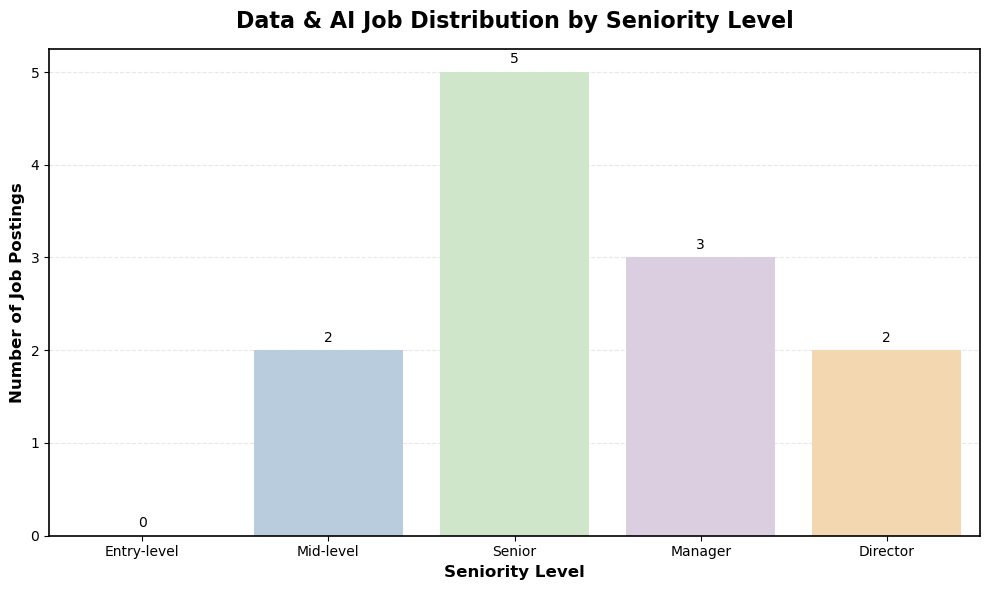

In [65]:
seniority_counts = (
    df_data_ai["primary_seniority"]
    .value_counts()
    .reindex(
        ["Entry-level", "Mid-level", "Senior", "Manager", "Director"],
        fill_value=0
    )
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=seniority_counts.index,
    y=seniority_counts.values,
    hue=seniority_counts.index,
    palette="Pastel1",
    legend=False
)

plt.title(
    "Data & AI Job Distribution by Seniority Level",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Seniority Level",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        padding=4,
        fontsize=10
    )

# Light horizontal grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Professional border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 14. Compare Skills Across Seniority Levels

Count the extracted skills within each primary seniority group and visualize the most frequent skills.

In [66]:
seniority_skill_counts = {}

for level in df_data_ai["primary_seniority"].unique():
    
    level_jobs = df_data_ai[
        df_data_ai["primary_seniority"] == level
    ]
    
    counter = Counter()
    
    for skills in level_jobs["extracted_skills"]:
        counter.update(skills)
    
    seniority_skill_counts[level] = counter

In [67]:
seniority_skill_df = pd.DataFrame(
    seniority_skill_counts
).fillna(0)

print(seniority_skill_df)

                         Senior  Manager  Director  Mid-level  Unknown
python                      3.0      3.0       0.0        2.0      0.0
excel                       4.0      3.0       2.0        0.0      0.0
pytorch                     1.0      0.0       0.0        0.0      0.0
machine learning            2.0      1.0       0.0        1.0      0.0
artificial intelligence     2.0      0.0       1.0        0.0      0.0
deep learning               1.0      0.0       0.0        0.0      0.0
sql                         3.0      3.0       0.0        2.0      0.0
power bi                    2.0      2.0       0.0        1.0      0.0
tableau                     2.0      0.0       0.0        2.0      0.0
git                         1.0      0.0       0.0        1.0      0.0
aws                         1.0      1.0       0.0        1.0      0.0
gcp                         1.0      0.0       0.0        1.0      0.0
azure                       0.0      2.0       0.0        1.0      0.0
spark 

In [68]:
top_seniority_skills = (
    seniority_skill_df.sum(axis=1)
    .sort_values(ascending=False)
    .head(12)
    .index
)

seniority_heatmap = seniority_skill_df.loc[
    top_seniority_skills
]

print(seniority_heatmap)

                         Senior  Manager  Director  Mid-level  Unknown
excel                       4.0      3.0       2.0        0.0      0.0
python                      3.0      3.0       0.0        2.0      0.0
sql                         3.0      3.0       0.0        2.0      0.0
power bi                    2.0      2.0       0.0        1.0      0.0
machine learning            2.0      1.0       0.0        1.0      0.0
tableau                     2.0      0.0       0.0        2.0      0.0
databricks                  0.0      2.0       0.0        2.0      0.0
artificial intelligence     2.0      0.0       1.0        0.0      0.0
aws                         1.0      1.0       0.0        1.0      0.0
azure                       0.0      2.0       0.0        1.0      0.0
snowflake                   0.0      2.0       0.0        1.0      0.0
git                         1.0      0.0       0.0        1.0      0.0


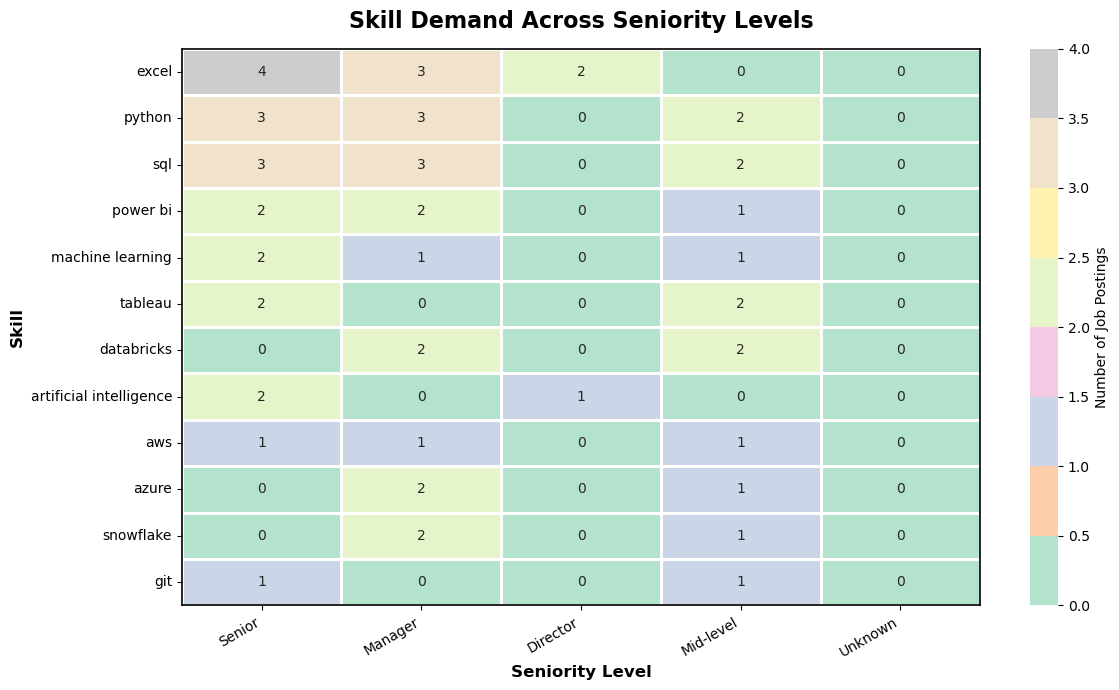

In [69]:
plt.figure(figsize=(12, 7))

ax = sns.heatmap(
    seniority_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Pastel2",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Number of Job Postings"}
)

plt.title(
    "Skill Demand Across Seniority Levels",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Seniority Level",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Skill",
    fontsize=12,
    fontweight="bold"
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

# Professional outer border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [70]:
print(
    df_data_ai["locationRestrictions"]
    .head(10)
    .to_string(index=False)
)

 [United States]
 [United States]
 [United States]
         [India]
[United Kingdom]
 [United States]
        [France]
 [United States]
         [India]
 [United States]


In [71]:
print(
    df_data_ai["locationRestrictions"]
    .value_counts()
    .head(20)
)

locationRestrictions
[United States]     6
[India]             2
[United Kingdom]    1
[France]            1
[Suriname]          1
[Canada]            1
[Greece]            1
Name: count, dtype: int64


## 15. Analyze Job Locations

Prepare location restrictions for readable summaries, then count the locations represented in the collected postings.

In [72]:
df_data_ai["location_text"] = df_data_ai["locationRestrictions"].apply(
    lambda x: ", ".join(x) if isinstance(x, list) else str(x)
)

In [73]:
print(
    df_data_ai[["title", "location_text"]]
    .head(15)
    .to_string(index=False)
)

                                                                           title  location_text
                                          AI Research Scientist, Agentic Systems  United States
                                                      Manager - Data Engineering  United States
                                                    Manager - Advanced Analytics  United States
                                                Machine Learning Scientist (ASR)          India
 Audit Technology and Data Analytics Expert, Director Analyst (REMOTE UK & EMEA) United Kingdom
Senior Analyst, Data & Analytics - No Surprises Act/Provider Reimbursements/SQL   United States
                                        Analytics Engineer, Finance and Modeling         France
                                                       Senior Analyst, Analytics  United States
                       Data Vault Engineer - VaultSpeed / Snowflake / Databricks          India
                         Data Solutions 

In [74]:
location_counts = (
    df_data_ai["location_text"]
    .value_counts()
)

print(location_counts.head(20))

location_text
United States     6
India             2
United Kingdom    1
France            1
Suriname          1
Canada            1
Greece            1
Name: count, dtype: int64


In [75]:
location_counter = Counter()

for locations in df_data_ai["locationRestrictions"]:
    
    if isinstance(locations, list):
        for location in locations:
            if location:
                location_counter[location] += 1

In [76]:
location_counter.most_common(15)

[('United States', 6),
 ('India', 2),
 ('United Kingdom', 1),
 ('France', 1),
 ('Suriname', 1),
 ('Canada', 1),
 ('Greece', 1)]

In [77]:
location_df = pd.DataFrame(
    location_counter.most_common(15),
    columns=["Location", "Job Count"]
)

print(location_df)

         Location  Job Count
0   United States          6
1           India          2
2  United Kingdom          1
3          France          1
4        Suriname          1
5          Canada          1
6          Greece          1


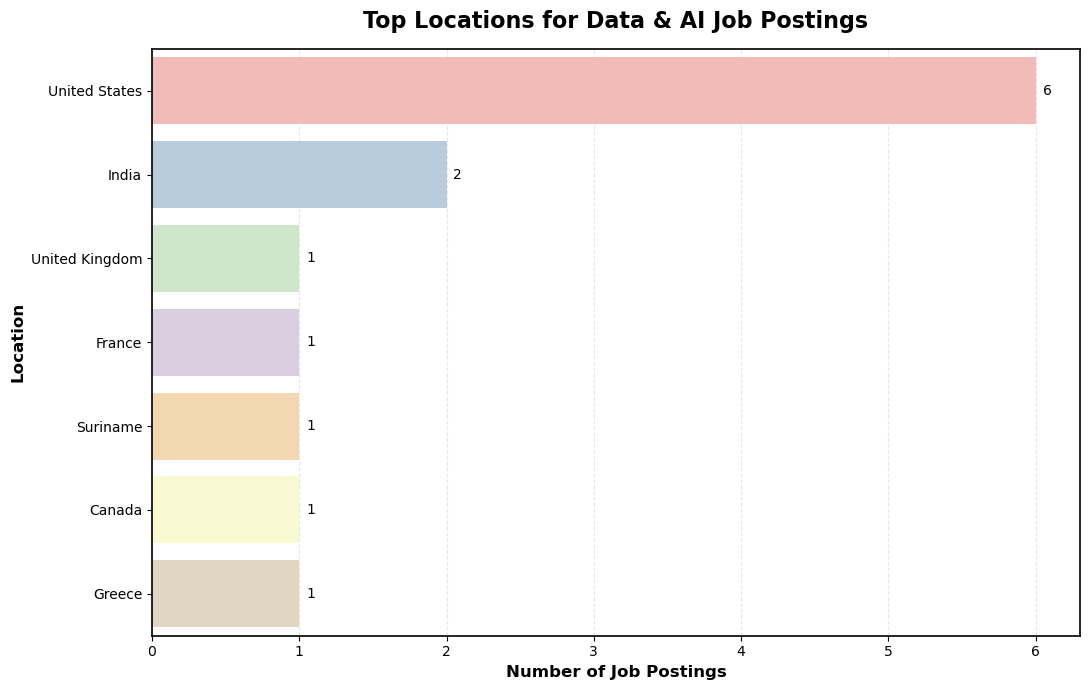

In [78]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=location_df,
    x="Job Count",
    y="Location",
    hue="Location",
    palette="Pastel1",
    legend=False
)

plt.title(
    "Top Locations for Data & AI Job Postings",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Location",
    fontsize=12,
    fontweight="bold"
)

# Add values
for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=10
    )

# Light grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Professional outer border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 16. Analyze Salary Information

Salary values are available for only a subset of postings. Review currency and salary period before making comparisons; do not treat different currencies or periods as directly equivalent.

In [79]:
salary_data = df_data_ai[
    df_data_ai["minSalary"].notna() &
    df_data_ai["maxSalary"].notna()
].copy()

print("Total Data & AI jobs:", len(df_data_ai))
print("Jobs with salary information:", len(salary_data))

Total Data & AI jobs: 13
Jobs with salary information: 8


In [80]:
print(
    salary_data[
        ["title", "minSalary", "maxSalary", "currency", "salaryPeriod"]
    ].head(10).to_string(index=False)
)

                                                  title  minSalary  maxSalary currency salaryPeriod
                 AI Research Scientist, Agentic Systems  120000.00  180000.00      USD       annual
                             Manager - Data Engineering  140000.00  160000.00      USD       annual
                           Manager - Advanced Analytics  160000.00  170000.00      USD       annual
               Analytics Engineer, Finance and Modeling   55000.00   70000.00      EUR       annual
                              Senior Analyst, Analytics   75000.00   95000.00      USD       annual
Data Solutions - Manager Data Modeling and Data Science      65.79      87.77      USD       hourly
                               Visier Practice Director  160000.00  170000.00      USD       annual
      Senior ML Engineer, AI Solutions (Greek-speaking)   53900.00   84700.00      EUR       annual


In [81]:
print(
    salary_data["currency"].value_counts()
)

currency
USD    6
EUR    2
Name: count, dtype: int64


In [82]:
salary_data["average_salary"] = (
    salary_data["minSalary"] +
    salary_data["maxSalary"]
) / 2

In [83]:
print(
    salary_data["salaryPeriod"].value_counts()
)

salaryPeriod
annual    7
hourly    1
Name: count, dtype: int64


In [84]:
print("Currency:")
print(salary_data["currency"].value_counts())

print("\nSalary Period:")
print(salary_data["salaryPeriod"].value_counts())

Currency:
currency
USD    6
EUR    2
Name: count, dtype: int64

Salary Period:
salaryPeriod
annual    7
hourly    1
Name: count, dtype: int64


In [85]:
print(
    salary_data["average_salary"].describe()
)

count         8.000000
mean     105859.597500
std       60632.041072
min          76.780000
25%       67600.000000
50%      117500.000000
75%      153750.000000
max      165000.000000
Name: average_salary, dtype: float64


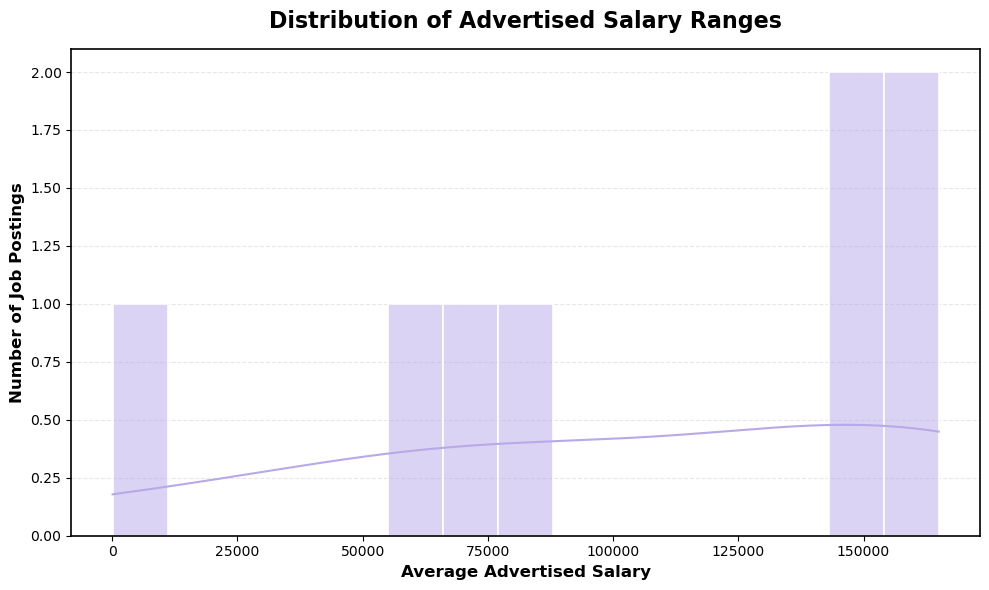

In [86]:
plt.figure(figsize=(10, 6))

ax = sns.histplot(
    data=salary_data,
    x="average_salary",
    bins=15,
    kde=True,
    color="#B8A9E8",
    edgecolor="white",
    linewidth=1.2
)

plt.title(
    "Distribution of Advertised Salary Ranges",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Average Advertised Salary",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [87]:
currency_counts = salary_data["currency"].value_counts()

print(currency_counts)

currency
USD    6
EUR    2
Name: count, dtype: int64


In [88]:
main_currency = currency_counts.index[0]

print("Main currency:", main_currency)

Main currency: USD


In [89]:
salary_main_currency = salary_data[
    salary_data["currency"] == main_currency
].copy()

print("Jobs in main currency:", len(salary_main_currency))

Jobs in main currency: 6


In [90]:
role_salary = (
    salary_main_currency
    .groupby("role")["average_salary"]
    .median()
    .sort_values(ascending=False)
)

print(role_salary)

role
Data Engineer    150000.0
Other Data/AI    150000.0
Name: average_salary, dtype: float64


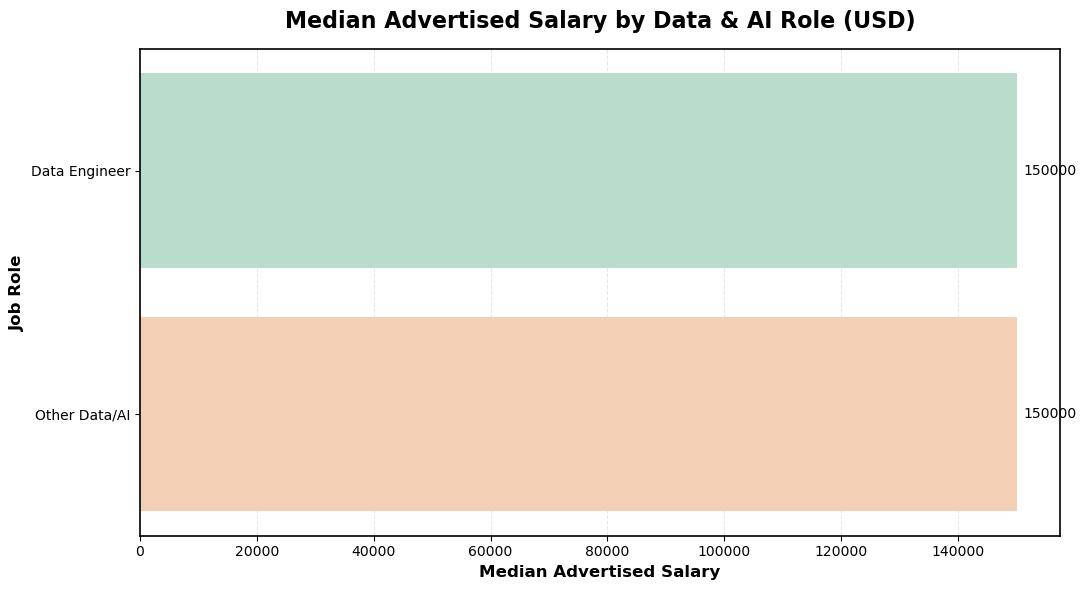

In [91]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=role_salary.values,
    y=role_salary.index,
    hue=role_salary.index,
    palette="Pastel2",
    legend=False
)

plt.title(
    f"Median Advertised Salary by Data & AI Role ({main_currency})",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Median Advertised Salary",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Job Role",
    fontsize=12,
    fontweight="bold"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [92]:
print(
    df_data_ai["employmentType"].value_counts()
)

employmentType
Full Time    12
Temporary     1
Name: count, dtype: int64


In [93]:
print(
    df_data_ai["employmentType"]
    .head(10)
    .to_string(index=False)
)

Full Time
Full Time
Full Time
Full Time
Full Time
Full Time
Full Time
Full Time
Full Time
Temporary


## 17. Analyze Employment Types

Count the employment arrangements represented in the Data & AI subset. A posting may list more than one type.

In [94]:
employment_counter = Counter()

for employment_types in df_data_ai["employmentType"]:
    
    if isinstance(employment_types, list):
        for employment_type in employment_types:
            if employment_type:
                employment_counter[employment_type] += 1
    else:
        employment_counter[str(employment_types)] += 1

print(employment_counter.most_common())

[('Full Time', 12), ('Temporary', 1)]


In [95]:
employment_df = pd.DataFrame(
    employment_counter.most_common(),
    columns=["Employment Type", "Job Count"]
)

print(employment_df)

  Employment Type  Job Count
0       Full Time         12
1       Temporary          1


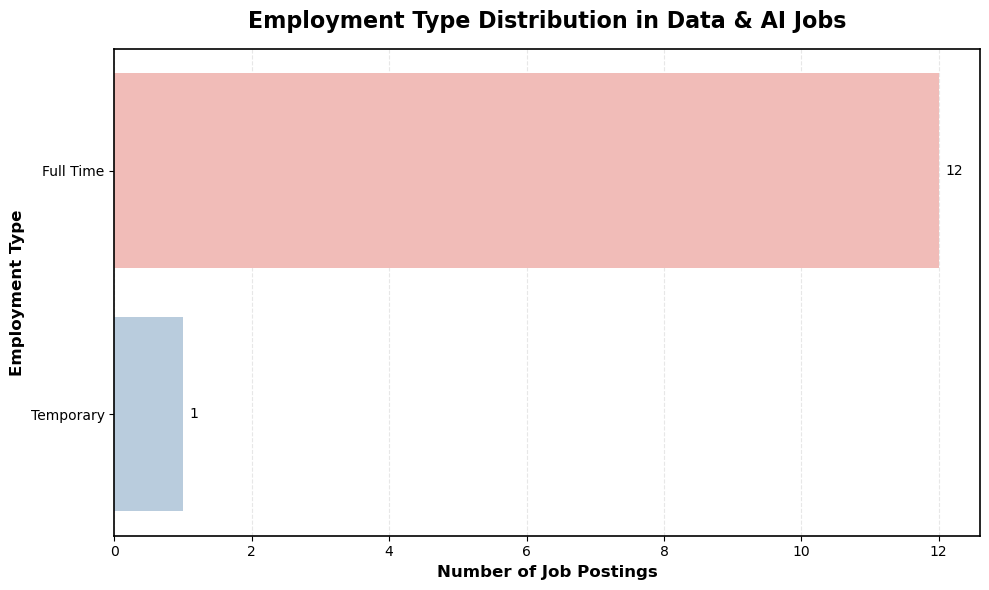

In [96]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=employment_df,
    x="Job Count",
    y="Employment Type",
    hue="Employment Type",
    palette="Pastel1",
    legend=False
)

plt.title(
    "Employment Type Distribution in Data & AI Jobs",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Employment Type",
    fontsize=12,
    fontweight="bold"
)

for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [97]:
print(
    df_data_ai["pubDate"].head(10)
)

24     1792380535
30     1792380441
31     1792380434
34     1792380432
50     1792379792
61     1792379553
115    1792376836
127    1792376230
132    1792376012
152    1792375342
Name: pubDate, dtype: int64


## 18. Analyze Publication Dates

Convert publication dates to datetime values and group postings by month. Because this is a single collection snapshot, this does not prove historical changes in skill demand.

In [98]:
df_data_ai["pubDate"] = pd.to_datetime(
    df_data_ai["pubDate"],
    errors="coerce"
)

print(
    df_data_ai["pubDate"].head()
)

24   1970-01-01 00:00:01.792380535
30   1970-01-01 00:00:01.792380441
31   1970-01-01 00:00:01.792380434
34   1970-01-01 00:00:01.792380432
50   1970-01-01 00:00:01.792379792
Name: pubDate, dtype: datetime64[ns]


In [99]:
print(
    "Missing publication dates:",
    df_data_ai["pubDate"].isna().sum()
)

Missing publication dates: 0


In [100]:
df_data_ai["publication_month"] = (
    df_data_ai["pubDate"]
    .dt.to_period("M")
    .astype(str)
)

In [101]:
monthly_jobs = (
    df_data_ai["publication_month"]
    .value_counts()
    .sort_index()
)

print(monthly_jobs)

publication_month
1970-01    13
Name: count, dtype: int64


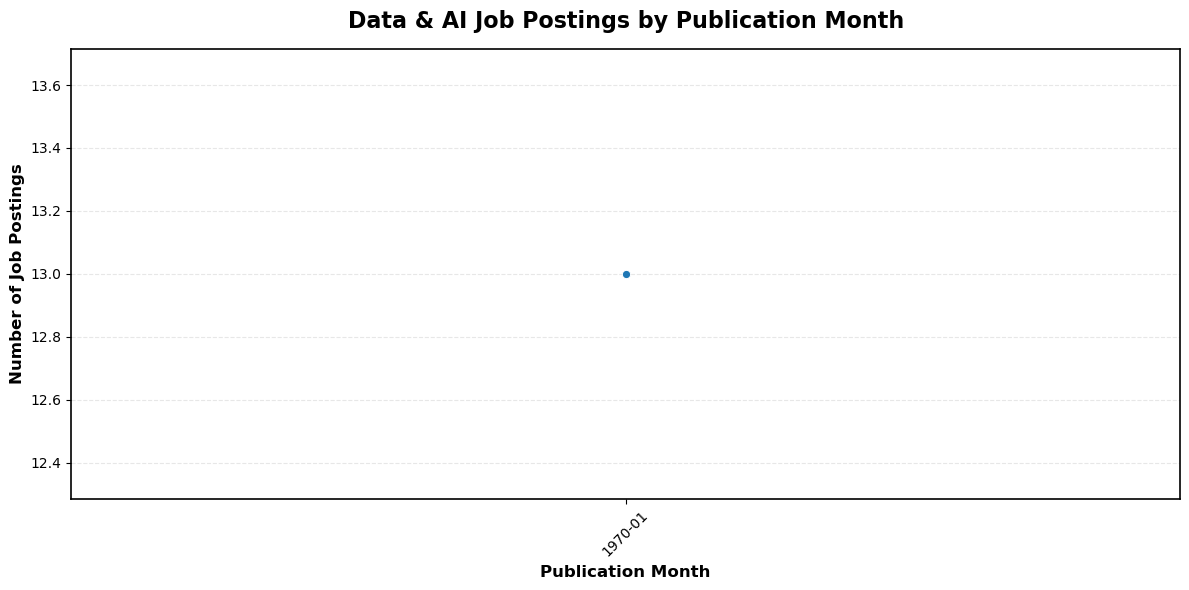

In [102]:
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    x=monthly_jobs.index,
    y=monthly_jobs.values,
    marker="o",
    linewidth=2.5
)

plt.title(
    "Data & AI Job Postings by Publication Month",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Publication Month",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.xticks(rotation=45)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 19. Analyze Companies

Identify companies appearing most frequently in this collected sample. These counts do not represent each company's total hiring activity.

In [103]:
company_counts = (
    df_data_ai["companyName"]
    .value_counts()
    .head(15)
)

print(company_counts)

companyName
Astrana Health          2
Crowdstrike             1
Wadhwani AI             1
Gartner                 1
Molina Healthcare       1
In Tandem               1
Spectrum Science        1
FormativGroup           1
dentsu international    1
TheHiveCareers          1
Next Generation Inc.    1
Sword Health            1
Name: count, dtype: int64


In [104]:
company_df = company_counts.reset_index()

company_df.columns = [
    "Company",
    "Job Count"
]

print(company_df)

                 Company  Job Count
0         Astrana Health          2
1            Crowdstrike          1
2            Wadhwani AI          1
3                Gartner          1
4      Molina Healthcare          1
5              In Tandem          1
6       Spectrum Science          1
7          FormativGroup          1
8   dentsu international          1
9         TheHiveCareers          1
10  Next Generation Inc.          1
11          Sword Health          1


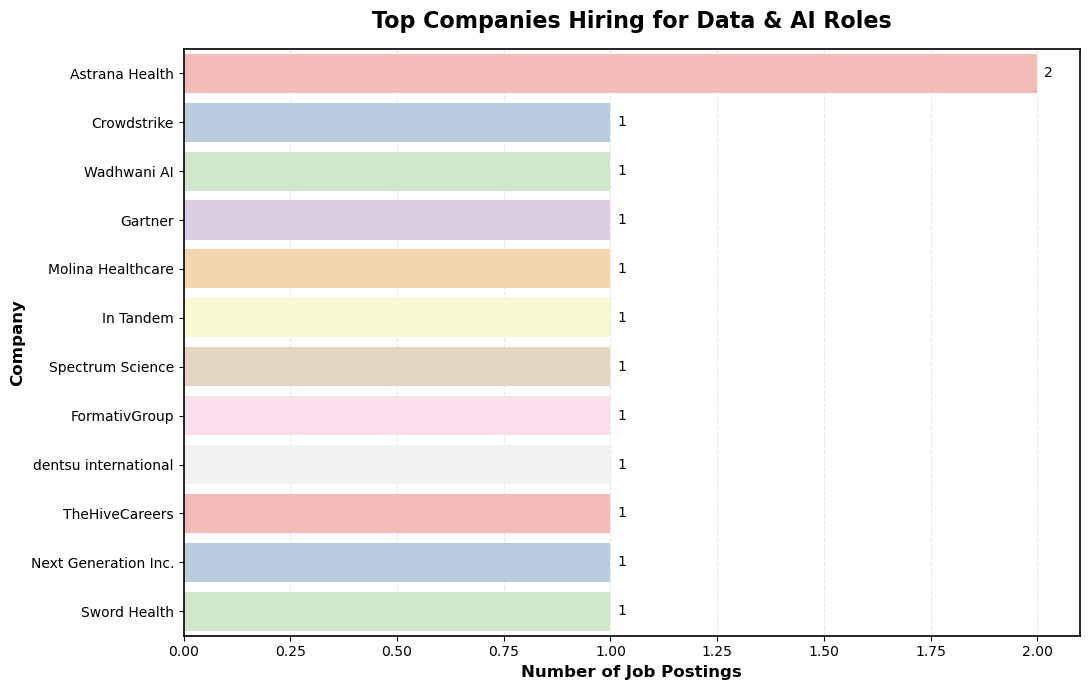

In [105]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=company_df,
    x="Job Count",
    y="Company",
    hue="Company",
    palette="Pastel1",
    legend=False
)

plt.title(
    "Top Companies Hiring for Data & AI Roles",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Company",
    fontsize=12,
    fontweight="bold"
)

for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 20. Analyze Job Categories

Count the categories associated with the filtered postings to see which categories are most represented.

In [106]:
category_counter = Counter()

for categories in df_data_ai["categories"]:
    
    if isinstance(categories, list):
        for category in categories:
            if category:
                category_counter[category] += 1
    else:
        category_counter[str(categories)] += 1

print(category_counter.most_common(20))

[('Data-Analyst', 3), ('Data-Scientist', 2), ('Machine-Learning-Scientist', 2), ('Analytics-Manager', 2), ('Data-Science', 2), ('Analytics-Analyst', 2), ('Marketing-Analyst', 2), ('AI-Research-Scientist', 1), ('Research-Scientist', 1), ('AI-Scientist', 1), ('Applied-AI-Research-Scientist', 1), ('AI-ML-Research-Scientist', 1), ('AI-Research-Scientist-Positions', 1), ('Research-AI-Scientist', 1), ('Agentic-Systems-Research', 1), ('Data-Engineering', 1), ('Engineering-Management', 1), ('Data-Pipeline-Engineering', 1), ('Technology-Leadership', 1), ('Data-Engineering-Manager', 1)]


In [107]:
category_df = pd.DataFrame(
    category_counter.most_common(15),
    columns=["Category", "Job Count"]
)

print(category_df)

                           Category  Job Count
0                      Data-Analyst          3
1                    Data-Scientist          2
2        Machine-Learning-Scientist          2
3                 Analytics-Manager          2
4                      Data-Science          2
5                 Analytics-Analyst          2
6                 Marketing-Analyst          2
7             AI-Research-Scientist          1
8                Research-Scientist          1
9                      AI-Scientist          1
10    Applied-AI-Research-Scientist          1
11         AI-ML-Research-Scientist          1
12  AI-Research-Scientist-Positions          1
13            Research-AI-Scientist          1
14         Agentic-Systems-Research          1


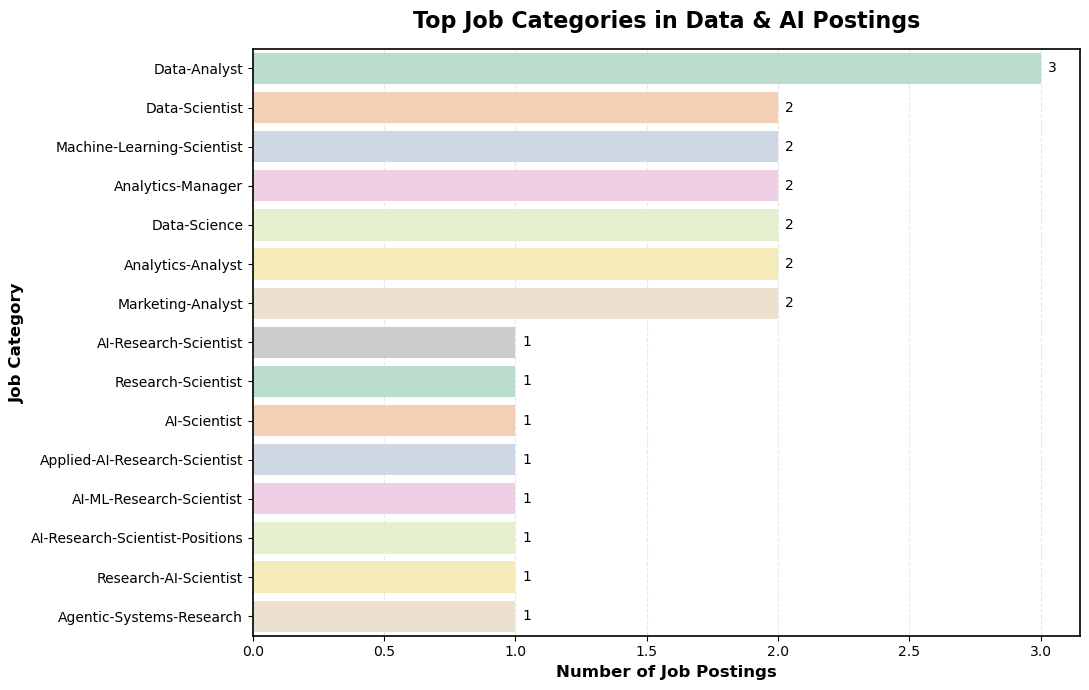

In [108]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=category_df,
    x="Job Count",
    y="Category",
    hue="Category",
    palette="Pastel2",
    legend=False
)

plt.title(
    "Top Job Categories in Data & AI Postings",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Job Postings",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Job Category",
    fontsize=12,
    fontweight="bold"
)

for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 21. Build a Project KPI Summary

Calculate a compact set of metrics describing the filtered dataset and the analysis completed.

In [109]:
total_jobs = len(df_data_ai)

unique_companies = df_data_ai["companyName"].nunique()

unique_roles = df_data_ai["role"].nunique()

unique_locations = location_df["Location"].nunique()

skills_identified = len(skill_df)

jobs_with_salary = len(salary_data)

print("Total Data & AI Jobs:", total_jobs)
print("Unique Companies:", unique_companies)
print("Job Role Categories:", unique_roles)
print("Locations:", unique_locations)
print("Skills Identified:", skills_identified)
print("Jobs with Salary:", jobs_with_salary)

Total Data & AI Jobs: 13
Unique Companies: 12
Job Role Categories: 3
Locations: 7
Skills Identified: 16
Jobs with Salary: 8


In [110]:
kpi_df = pd.DataFrame({
    "Metric": [
        "Data & AI Job Postings",
        "Unique Companies",
        "Job Role Categories",
        "Locations",
        "Skills Identified",
        "Jobs with Salary Information"
    ],
    
    "Value": [
        total_jobs,
        unique_companies,
        unique_roles,
        unique_locations,
        skills_identified,
        jobs_with_salary
    ]
})

kpi_df

,Metric,Value
0,Data & AI Job Postings,13
1,Unique Companies,12
2,Job Role Categories,3
3,Locations,7
4,Skills Identified,16
5,Jobs with Salary Information,8


In [111]:
kpi_df = pd.DataFrame({
    "Metric": [
        "Data & AI Job Postings",
        "Unique Companies",
        "Job Role Categories",
        "Locations",
        "Skills Identified",
        "Jobs with Salary Information"
    ],
    
    "Value": [
        total_jobs,
        unique_companies,
        unique_roles,
        unique_locations,
        skills_identified,
        jobs_with_salary
    ]
})

kpi_df

,Metric,Value
0,Data & AI Job Postings,13
1,Unique Companies,12
2,Job Role Categories,3
3,Locations,7
4,Skills Identified,16
5,Jobs with Salary Information,8


In [112]:
kpi_df.to_csv(
    "../data/project_kpis.csv",
    index=False
)

print("KPI summary saved successfully.")

KPI summary saved successfully.


In [113]:
top_skills = skill_df.head(10)

print(top_skills)

                     Skill  Job Count   Demand %
0                    excel          9  69.230769
1                   python          8  61.538462
2                      sql          8  61.538462
3                 power bi          5  38.461538
4         machine learning          4  30.769231
5               databricks          4  30.769231
6                  tableau          4  30.769231
7  artificial intelligence          3  23.076923
8                      aws          3  23.076923
9                    azure          3  23.076923


In [114]:
top_role = df_data_ai["role"].value_counts().idxmax()
top_role_count = df_data_ai["role"].value_counts().max()

print("Most common role:", top_role)
print("Number of postings:", top_role_count)

Most common role: Other Data/AI
Number of postings: 10


In [115]:
top_seniority = (
    df_data_ai["primary_seniority"]
    .value_counts()
    .idxmax()
)

top_seniority_count = (
    df_data_ai["primary_seniority"]
    .value_counts()
    .max()
)

print("Most common seniority:", top_seniority)
print("Number of postings:", top_seniority_count)

Most common seniority: Senior
Number of postings: 5


In [116]:
top_employment = employment_df.iloc[0]

print(
    "Most common employment type:",
    top_employment["Employment Type"]
)

print(
    "Number of postings:",
    top_employment["Job Count"]
)

Most common employment type: Full Time
Number of postings: 12


In [117]:
top_location = location_df.iloc[0]

print(
    "Most common location:",
    top_location["Location"]
)

print(
    "Number of postings:",
    top_location["Job Count"]
)

Most common location: United States
Number of postings: 6


In [118]:
top_location = location_df.iloc[0]

print(
    "Most common location:",
    top_location["Location"]
)

print(
    "Number of postings:",
    top_location["Job Count"]
)

Most common location: United States
Number of postings: 6


In [119]:
top_company = company_df.iloc[0]

print(
    "Most represented company:",
    top_company["Company"]
)

print(
    "Number of postings:",
    top_company["Job Count"]
)

Most represented company: Astrana Health
Number of postings: 2


In [120]:
top_skill_demand = skill_df.head(15)[
    ["Skill", "Job Count", "Demand %"]
].copy()

top_skill_demand["Demand %"] = (
    top_skill_demand["Demand %"].round(2)
)

print(top_skill_demand.to_string(index=False))

                  Skill  Job Count  Demand %
                  excel          9     69.23
                 python          8     61.54
                    sql          8     61.54
               power bi          5     38.46
       machine learning          4     30.77
             databricks          4     30.77
                tableau          4     30.77
artificial intelligence          3     23.08
                    aws          3     23.08
                  azure          3     23.08
              snowflake          3     23.08
                  spark          2     15.38
                    git          2     15.38
                    gcp          2     15.38
                pytorch          1      7.69


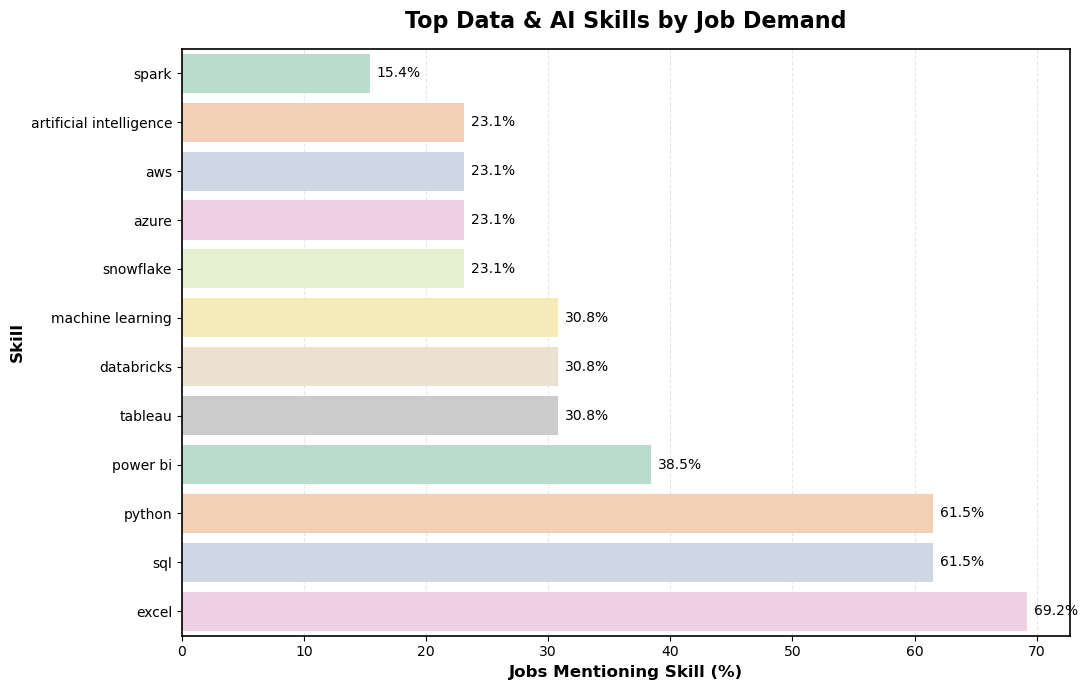

In [121]:
plt.figure(figsize=(11, 7))

plot_data = skill_df.head(12).sort_values(
    "Demand %",
    ascending=True
)

ax = sns.barplot(
    data=plot_data,
    x="Demand %",
    y="Skill",
    hue="Skill",
    palette="Pastel2",
    legend=False
)

plt.title(
    "Top Data & AI Skills by Job Demand",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Jobs Mentioning Skill (%)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Skill",
    fontsize=12,
    fontweight="bold"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=5,
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [122]:
print(
    skill_df[
        ["Skill", "Job Count", "Demand %"]
    ].head(5).to_string(index=False)
)

           Skill  Job Count  Demand %
           excel          9 69.230769
          python          8 61.538462
             sql          8 61.538462
        power bi          5 38.461538
machine learning          4 30.769231


## 22. Prepare Key Findings

Collect the leading results from the analyses so they can be summarized consistently in the final report.

In [123]:
print("=" * 60)
print("       DATA & AI JOB MARKET — KEY FINDINGS")
print("=" * 60)

print("\n1. DATASET")
print(f"Data & AI job postings analyzed: {len(df_data_ai)}")
print(f"Unique companies: {df_data_ai['companyName'].nunique()}")

print("\n2. TOP SKILLS")
for _, row in skill_df.head(5).iterrows():
    print(
        f"{row['Skill']}: "
        f"{int(row['Job Count'])} jobs "
        f"({row['Demand %']:.1f}%)"
    )

print("\n3. MOST COMMON ROLE")
print(
    f"{top_role}: "
    f"{top_role_count} postings"
)

print("\n4. MOST COMMON SENIORITY")
print(
    f"{top_seniority}: "
    f"{top_seniority_count} postings"
)

print("\n5. TOP LOCATION")
print(
    f"{top_location['Location']}: "
    f"{int(top_location['Job Count'])} postings"
)

print("\n6. TOP COMPANY")
print(
    f"{top_company['Company']}: "
    f"{int(top_company['Job Count'])} postings"
)

print("\n7. TOP EMPLOYMENT TYPE")
print(
    f"{top_employment['Employment Type']}: "
    f"{int(top_employment['Job Count'])} postings"
)

print("\n8. SALARY DATA")
print(
    f"Jobs with salary information: "
    f"{len(salary_data)}"
)

print("\n" + "=" * 60)

       DATA & AI JOB MARKET — KEY FINDINGS

1. DATASET
Data & AI job postings analyzed: 13
Unique companies: 12

2. TOP SKILLS
excel: 9 jobs (69.2%)
python: 8 jobs (61.5%)
sql: 8 jobs (61.5%)
power bi: 5 jobs (38.5%)
machine learning: 4 jobs (30.8%)

3. MOST COMMON ROLE
Other Data/AI: 10 postings

4. MOST COMMON SENIORITY
Senior: 5 postings

5. TOP LOCATION
United States: 6 postings

6. TOP COMPANY
Astrana Health: 2 postings

7. TOP EMPLOYMENT TYPE
Full Time: 12 postings

8. SALARY DATA
Jobs with salary information: 8



# Key Findings

## 1. Skill Demand
The analysis identifies the most frequently mentioned technical skills across the collected Data & AI job postings. These skills provide an indication of the technologies commonly appearing in the sampled job market.

## 2. Skill Combinations
Several skills frequently appear together in the same job postings. This shows that employers often look for combinations of complementary technical skills rather than a single technology.

## 3. Role Distribution
The dataset contains multiple Data & AI roles, including Data Analyst, Data Scientist, Data Engineer, Machine Learning, AI Engineer, Python Developer, and Business Intelligence roles.

## 4. Seniority
The collected postings cover different career levels, from entry-level positions to senior, manager, and director-level roles. This provides an overview of the experience levels represented in the dataset.

## 5. Geographic Distribution
The location analysis identifies the locations that occur most frequently among the collected job postings. This helps understand the geographic distribution of the sampled opportunities.

## 6. Salary
Salary information was available only for a subset of the collected jobs. Because salary values may use different currencies and salary periods, salary comparisons were restricted to comparable data.

## 7. Employment Type
The employment analysis shows which employment arrangements are most frequently represented in the collected Data & AI postings.

## 8. Companies
The company analysis identifies organizations that appear most frequently in the collected postings. These counts represent the collected dataset and should not be interpreted as overall company hiring volume.

## 9. Publication Trends
The publication-date analysis shows how the collected job postings are distributed across publication months. Since this project currently uses a single data-collection snapshot, it does not establish long-term changes in skill demand.

## Overall Conclusion

This project demonstrates how job-market data can be collected through an API, cleaned and transformed using Python, analyzed using exploratory data analysis techniques, and converted into meaningful insights about Data & AI skills, roles, seniority, locations, employment types, companies, and salary information.

The results represent the Data & AI job postings collected from the selected source at the time of analysis. Therefore, the findings describe the sampled dataset rather than the entire global job market.

# Project Limitations

- The analysis is based on a limited sample of collected job postings.
- The dataset represents job postings available through the selected source at the time of collection.
- Salary information is missing for many postings.
- Salary values may use different currencies and salary periods.
- Skill extraction is keyword-based, so some skills may be missed because of different wording or synonyms.
- The current dataset represents a single collection snapshot and therefore cannot independently establish historical skill evolution.
- Job categories and role classifications depend on the available job-posting metadata and the classification rules used in this project.